In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
t_half = 10             #half life
lam = np.log(2)/t_half
p = 1 - np.exp(-lam)                 # Decay Probability, dt = 1
q = 1 - p               # Survival Probability

In [ ]:
N = 1000                # Initial Number of atoms

In [ ]:
def decay(N):
  population = []
  for t in range(100):
    r = np.random.random(N)
    survive = np.sum(r < q)         #No. of atoms survived
    population.append(survive)
    N = survive                     #Upgrade for next time step
  return population

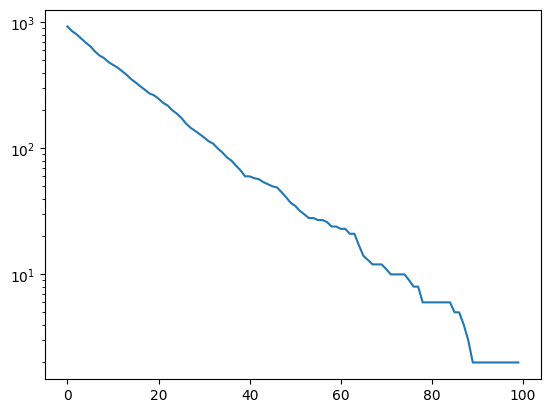

In [ ]:
plt.semilogy()
plt.plot(range(100), decay(N))

In [ ]:
mean_decay = np.mean(np.array([decay(N) for i in range(1000)]), axis = 0)
std_decay = np.std(np.array([decay(N) for i in range(1000)]), axis = 0)

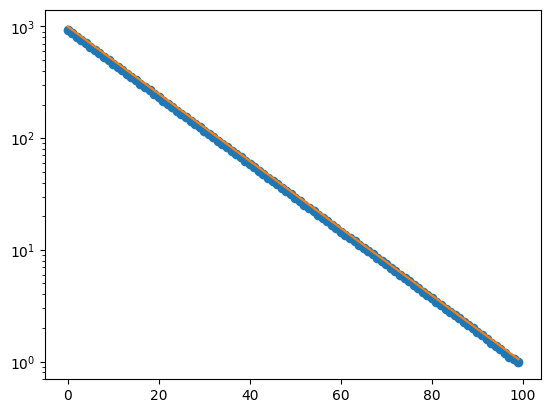

In [ ]:
plt.semilogy()
T = np.arange(100)
plt.plot(T, mean_decay, 'o')
exact = N*np.exp(-lam*T)
plt.plot(T, exact)

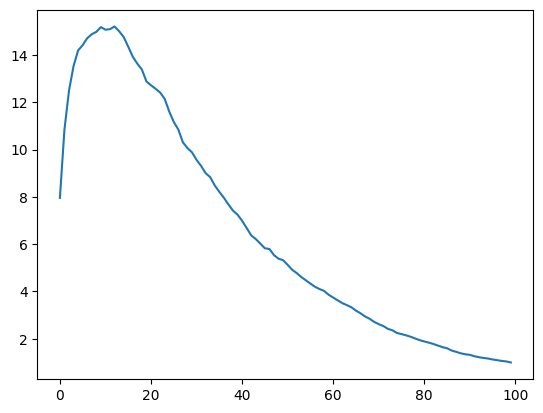

In [ ]:
plt.plot(T, std_decay)

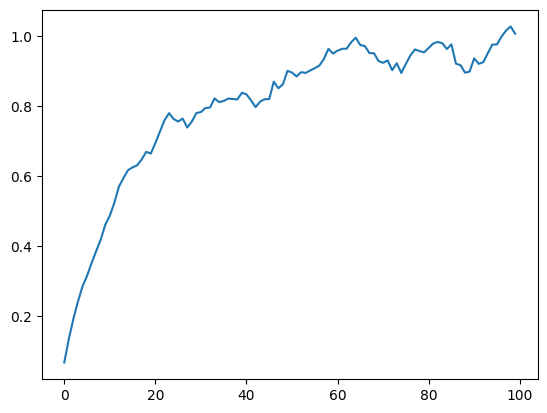

In [ ]:
plt.plot(T, std_decay**2/mean_decay)

In [ ]:
def run(p, record_start, runs=1000):
    q = 1 - p
    results = []
    for _ in range(runs):
        n = N
        pop = []
        for t in range(100):
            if record_start: pop.append(n)
            n = np.sum(np.random.random(n) < q)
            if not record_start: pop.append(n)
        results.append(pop)
    return np.mean(results, axis=0)

def measure(mean):
    mask = mean > 10
    slope = np.polyfit(T[mask], np.log(mean[mask]), 1)[0]
    half_life = np.log(2) / -slope
    exact = N * np.exp(-lam * T)
    error = np.mean(np.abs(mean[mask] - exact[mask]) / exact[mask]) * 100
    return half_life, error

versions = [("Original tutorial", lam, False),
            ("Fixed decay chance", 1 - np.exp(-lam), False),
            ("Both fixes", 1 - np.exp(-lam), True)]

for label, p_val, start in versions:
    hl, err = measure(run(p_val, start))
    print(f"{label}: half-life = {hl:.2f} steps, mean error = {err:.1f}%")

Original tutorial: half-life = 9.68 steps, mean error = 13.6%
Fixed decay chance: half-life = 10.01 steps, mean error = 6.4%
Both fixes: half-life = 10.00 steps, mean error = 0.1%
